Just playing around with the APi

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')

import pandas as pd, sklearn, requests, matplotlib
# checking python path
print(sys.executable)
# checking versions 
print(pd.__version__, sklearn.__version__)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
/Users/biancajavier/github/biancacchino/bvb-title-predictor/.venv/bin/python
3.0.6 1.9.1


In [118]:
# fetching data, retrieves all matches from 2020 season of the  matchday
r = requests.get(f'https://api.openligadb.de/getmatchdata/bl1/2020/', timeout=10)
r.raise_for_status()
matches = r.json()
len(matches), matches

(306,
 [{'matchID': 58577,
   'matchDateTime': '2020-09-18T20:30:00',
   'timeZoneID': 'W. Europe Standard Time',
   'leagueId': 4442,
   'leagueName': '1. Fußball-Bundesliga 2020/2021',
   'leagueSeason': 2020,
   'leagueShortcut': 'bl1',
   'matchDateTimeUTC': '2020-09-18T18:30:00Z',
   'group': {'groupName': '1. Spieltag', 'groupOrderID': 1, 'groupID': 36486},
   'team1': {'teamId': 40,
    'teamName': 'FC Bayern München',
    'shortName': 'Bayern',
    'teamIconUrl': 'https://upload.wikimedia.org/wikipedia/commons/1/1f/Logo_FC_Bayern_M%C3%BCnchen_%282002%E2%80%932017%29.svg',
    'teamGroupName': None},
   'team2': {'teamId': 9,
    'teamName': 'FC Schalke 04',
    'shortName': 'S04',
    'teamIconUrl': 'https://upload.wikimedia.org/wikipedia/commons/9/97/FC_Schalke_04_Logo.png',
    'teamGroupName': None},
   'lastUpdateDateTime': '2020-09-20T16:15:35.617',
   'matchIsFinished': True,
   'matchResults': [{'resultID': 92144,
     'resultName': 'Endergebnis',
     'pointsTeam1': 8,


In [58]:
m = matches[0]
m['team2']['teamName'], m['group']['groupOrderID'], m['matchIsFinished']



('FC Schalke 04', 1, True)

In [60]:
for result in m['matchResults']:
    print(result['pointsTeam1'], result['pointsTeam2'])


def full_time(match):
    for result in match['matchResults']:
        # 2 is the score after full time, 1 is halftime
        if result['resultTypeID'] == 2:
            return result['pointsTeam1'], result['pointsTeam2']
    return None, None

full_time(m)
            

8 0
3 0


(8, 0)

In [61]:
home_goals, away_goals = full_time(m) # unpacks the tuple
row = {
    'season': m['leagueSeason'],
    'matchday': m['group']['groupOrderID'],
    'date': m['matchDateTime'],
    'home_team': m['team1']['teamName'],
    'away_team': m['team2']['teamName'],
    'home_goals': home_goals,
    'away_goals': away_goals,
    'finished': m['matchIsFinished']
}
row




{'season': 2020,
 'matchday': 1,
 'date': '2020-09-18T20:30:00',
 'home_team': 'FC Bayern München',
 'away_team': 'FC Schalke 04',
 'home_goals': 8,
 'away_goals': 0,
 'finished': True}

In [62]:
rows = []
for m in matches:
    home_goals, away_goals = full_time(m)
    rows.append({
        'season': m['leagueSeason'],
        'matchday': m['group']['groupOrderID'],
        'date': m['matchDateTime'],
        'home_team': m['team1']['teamName'],
        'away_team': m['team2']['teamName'],
        'home_goals': home_goals,
        'away_goals': away_goals,
        'finished': m['matchIsFinished']
    })

df = pd.DataFrame(rows)
df

,season,matchday,date,home_team,away_team,home_goals,away_goals,finished
0,2020,1,2020-09-18T20:30:00,FC Bayern München,FC Schalke 04,8,0,True
1,2020,1,2020-09-19T15:30:00,Eintracht Frankfurt,DSC Arminia Bielefeld,1,1,True
2,2020,1,2020-09-19T15:30:00,1. FC Köln,TSG Hoffenheim,2,3,True
3,2020,1,2020-09-19T15:30:00,VfB Stuttgart,SC Freiburg,2,3,True
4,2020,1,2020-09-19T15:30:00,1. FC Union Berlin,FC Augsburg,1,3,True
...,...,...,...,...,...,...,...,...
301,2020,34,2021-05-22T15:30:00,1. FC Köln,FC Schalke 04,1,0,True
302,2020,34,2021-05-22T15:30:00,VfB Stuttgart,DSC Arminia Bielefeld,0,2,True
303,2020,34,2021-05-22T15:30:00,1. FC Union Berlin,RB Leipzig,2,1,True
304,2020,34,2021-05-22T15:30:00,SV Werder Bremen,Borussia Mönchengladbach,2,4,True


In [64]:
df.shape 
# df.matchday.nunique()
# df.finished.all()

(306, 8)

In [ ]:
bvb_home = df[df.home_team == 'Borussia Dortmund'] # rows where bvb is the home team
(bvb_home.home_goals > bvb_home.away_goals).sum() # bvb number of wins home

np.int64(11)

In [ ]:
bvb_away = df[df.away_team == 'Borussia Dortmund'] # rows where bvb is the away team
(bvb_away.home_goals < bvb_away.away_goals).sum() # bvb number of wins away

np.int64(9)

In [114]:
bvb_draw_home = df[df.home_team == 'Borussia Dortmund']
(bvb_draw_home.home_goals == bvb_draw_home.away_goals).sum() # bvb number of draws
bvb_draw_away = df[df.away_team == 'Borussia Dortmund']
(bvb_draw_away.home_goals == bvb_draw_away.away_goals).sum() # bvb number of draws away



np.int64(2)

In [117]:
bvb_home = df[df.home_team == 'Borussia Dortmund']
bvb_away = df[df.away_team == 'Borussia Dortmund']

home_wins = (bvb_home.home_goals > bvb_home.away_goals).sum() # bvb number of wins home
away_wins = (bvb_away.home_goals < bvb_away.away_goals).sum() # bvb number of wins away
home_draws = (bvb_draw_home.home_goals == bvb_draw_home.away_goals).sum() # bvb number of draws home
away_draws = (bvb_draw_away.home_goals == bvb_draw_away.away_goals).sum() # bvb number of draws away

draws = home_draws + away_draws

bvb_points_2020 = ((home_wins + away_wins) * 3) + draws 
bvb_points_2020




np.int64(64)

this is teh expected score for the home team, 0 and 1

In [ ]:
HOME_ADV = 60 # home advantage in ELO
def expected_score(r_home, r_away):
    return  1 / (1+10 ** ((r_away - r_home - HOME_ADV) / 400))

expected_score(1500, 1500) # 0.585 equal but home advantage
expected_score(1500, 1560) # 0.57
expected_score(1700, 1400) # 0.8 high strong home team

0.5

In [12]:
HOME_ADVANTAGE = 60   # Elo points added to the home team
K_FACTOR = 20         # how far one match can move a rating

def expected_score(home_rating, away_rating):
    return 1 / (1 + 10 ** ((away_rating - home_rating - HOME_ADVANTAGE) / 400))

def actual_score(home_goals, away_goals):
    # 1 for a home win, 0.5 for a draw, 0 for an away win
    if home_goals > away_goals:
        return 1
    elif home_goals == away_goals:
        return 0.5
    else:
        return 0

def update(home_rating, away_rating, home_goals, away_goals):
    expected = expected_score(home_rating, away_rating)
    actual = actual_score(home_goals, away_goals)
    rating_change = K_FACTOR * (actual - expected)
    return home_rating + rating_change, away_rating - rating_change


In [13]:
print(update(1500, 1500, 2, 0))       # about (1508.3, 1491.7)
print(update(1500, 1500, 0, 0))       # about (1498.3, 1501.7)
print(sum(update(1600, 1450, 1, 3)))  # 3050.0


(1508.2900264265638, 1491.7099735734362)
(1498.2900264265638, 1501.7099735734362)
3050.0


In [37]:
import sys
sys.path.append('..')
from src.data import load_all
import pandas as pd
LEAGUE_AVERAGE = 1500
SECOND_DIVISION_RATING = 1400
SUMMER_KEEP = 0.8        # share of a rating's distance from 1500 kept over the summer

matches = load_all()
matches['date'] = pd.to_datetime(matches['date'])                     # convert to real dates (pd.to_datetime)
matches = matches.sort_values('date').reset_index(drop=True)

home_elo_before = []
away_elo_before = []
current_season = None
first_season = matches.season.min()
ratings = {team: LEAGUE_AVERAGE for team in set(matches.loc[matches.season == first_season, 'home_team'])}
for match in matches.itertuples():
    if match.season != current_season:
        teams_this_season = set(matches.loc[matches.season == match.season, 'home_team'])
        for team, rating in ratings.items():
            target = LEAGUE_AVERAGE if team in teams_this_season else SECOND_DIVISION_RATING
            ratings[team] = target + SUMMER_KEEP * (rating - target)
        current_season = match.season

    home_rating = ratings.get(match.home_team, SECOND_DIVISION_RATING)
    away_rating = ratings.get(match.away_team, SECOND_DIVISION_RATING)

    # 1. save BEFORE updating (no leakage)
    home_elo_before.append(home_rating)
    away_elo_before.append(away_rating)

    # 2. update only if the match has been played
    if match.finished:
        new_home_rating, new_away_rating = update(
            home_rating, away_rating, match.home_goals, match.away_goals
        )
        ratings[match.home_team] = new_home_rating
        ratings[match.away_team] = new_away_rating

matches['home_elo_before'] = home_elo_before
matches['away_elo_before'] = away_elo_before
matches[['date', 'home_team', 'away_team', 'home_elo_before', 'away_elo_before']].tail()

print(update(1500, 1500, 2, 0))       # about (1508.3, 1491.7)
print(update(1500, 1500, 0, 0))       # about (1498.3, 1501.7)
print(sum(update(1600, 1450, 1, 3)))  # 3050.0



Loading 2003
Loading 2004
Loading 2005
Loading 2006
Loading 2007
Loading 2008
Loading 2009
Loading 2010
Loading 2011
Loading 2012
Loading 2013
Loading 2014
Loading 2015
Loading 2016
Loading 2017
Loading 2018
Loading 2019
Loading 2020
Loading 2021
Loading 2022
Loading 2023
Loading 2024
Loading 2025
Loading 2026
(1508.2900264265638, 1491.7099735734362)
(1498.2900264265638, 1501.7099735734362)
3050.0


In [21]:
print(len(matches), matches['home_elo_before'].isna().sum())

7344 0


In [22]:
pd.Series(ratings).sort_values(ascending=False).head(5)

FC Bayern München      1710.325567
Borussia Dortmund      1632.059281
Bayer 04 Leverkusen    1589.621642
RB Leipzig             1566.331426
VfB Stuttgart          1527.810461
dtype: float64

In [40]:
bvb = matches[
    (matches.home_team == 'Borussia Dortmund') |
    (matches.away_team == 'Borussia Dortmund')
].copy()

bvb['bvb_elo'] = bvb.home_elo_before.where(
    bvb.home_team == 'Borussia Dortmund',
    bvb.away_elo_before,
)
bvb = bvb[bvb.season >= 2003]
# they sold erling haaland in 2022
bvb_2022 = bvb[bvb.season == 2022]
# they sold jude bellingham in 2023
bvb_2023 = bvb[bvb.season == 2023]
bvb_2012 = bvb[bvb.season == 2012]
# bvb_2012.head(1)

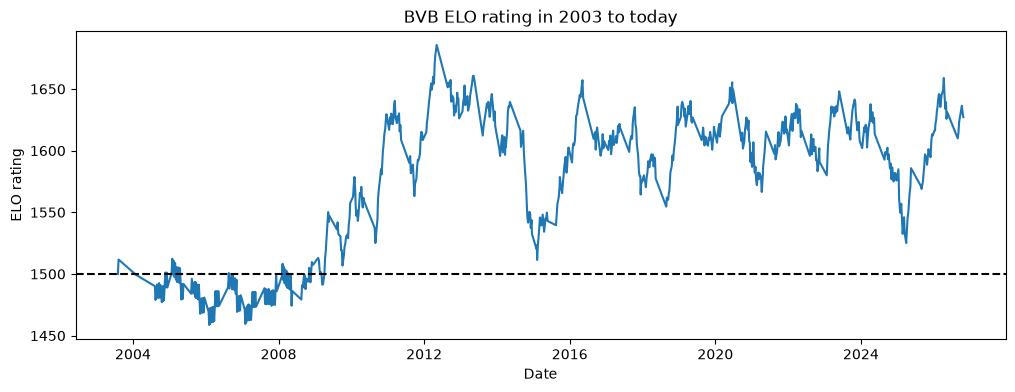

In [41]:
import matplotlib.pyplot as plt
played = bvb[bvb.finished]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(played.date, played.bvb_elo)
ax.axhline(LEAGUE_AVERAGE, color='black', linestyle='--')
ax.set_title('BVB ELO rating in 2003 to today')
ax.set_xlabel('Date')
ax.set_ylabel('ELO rating')
plt.show()

In [36]:
print(len(matches), matches['home_elo_before'].isna().sum())

7344 0
